# Sprint 1 - Data Cleaning
I am doing Laptop Price Analysis. Main column for business is Price. I will clean the raw data step by step and make it ready for analysis.

## Step 1 - Business Understanding
- Business aim: electronics shop wants to know how laptop features decide price.
- My work: clean data, then study RAM, Storage, Brand, Processor, Screen, Weight with Price.
- Main metric: Price.
- Why important: if shop knows which feature increases price, they can set correct price and keep correct stock.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv('../Laptop_for_messy.csv', dtype=str, keep_default_na=False)
print(df_raw.shape)
print(df_raw.columns.tolist())

(1020, 7)
['Brand', 'Processor_Speed', 'RAM_Size', 'Storage_Capacity', 'Screen_Size', 'Weight', 'Price']


There are 1020 rows and 7 columns. Columns are Brand, Processor_Speed, RAM_Size, Storage_Capacity, Screen_Size, Weight, Price.

In [2]:
# basic structure
df_raw.head()


,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Lenovo,1.6508802099764095,16,256,16.002751705512964,2.5964421828122086,9788.823673511592
1,Acer,3.0428624665100754,4,256,13.374247781442756,2.625198720854995,8975.326466281276
2,Acer,3.679458916480504,8,512,15.44338833955706,2.207460703155504,17397.54904187063
3,Asus,2.367383004740569,32,256,11.710954152610404,2.8619801495267057,10605.76645913327
4,Asus,2.174374028792474,32,512,16.642515243804482,3.536644123031155,18293.33190003984


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Brand             1020 non-null   str  
 1   Processor_Speed   1020 non-null   str  
 2   RAM_Size          1020 non-null   str  
 3   Storage_Capacity  1020 non-null   str  
 4   Screen_Size       1020 non-null   str  
 5   Weight            1020 non-null   str  
 6   Price             1020 non-null   str  
dtypes: str(7)
memory usage: 132.6 KB


In [4]:
df_raw.describe(include='all')


,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
count,1020,1020,1020,1020,1020,1020,1020
unique,18,983,12,10,983,982,983
top,Dell,,32,256,,,
freq,208,15,272,352,16,15,15


All columns are object type because numbers are stored as text. Brand has extra spaces and small/capital differences like '  Acer' and 'hp'. So I need to clean it.

In [5]:
# check unique values
print(df_raw.nunique())
print(df_raw['Brand'].value_counts(dropna=False).head(20))


Brand                18
Processor_Speed     983
RAM_Size             12
Storage_Capacity     10
Screen_Size         983
Weight              982
Price               983
dtype: int64
Brand
Dell          208
Asus          205
Acer          204
HP            194
Lenovo        186
  Acer          4
  Asus          4
  Lenovo        3
NA              2
N/A             2
-               1
hp              1
  Dell          1
missing         1
asus            1
null            1
dell            1
NULL            1
Name: count, dtype: int64


## Step 2 - Missing values
Some cells have blank, NA, N/A, null, missing, -. I will count them.

In [6]:
missing_list = ['', 'na', 'n/a', 'null', 'missing', '-', 'nan', 'none', 'nil', '-1']

for c in df_raw.columns:
    s = df_raw[c].astype(str).str.strip().str.lower()
    n = s.isin(missing_list).sum()
    print(c, n)


Brand 8
Processor_Speed 24
RAM_Size 24
Storage_Capacity 25
Screen_Size 25
Weight 24
Price 24


What I found: each number column has around 24 missing values. Brand has 8 missing. This is only about 2 percent, so I will fill them, not delete rows. For numbers I will use median because median does not change with big outliers. For Brand I will use mode (most common value).

## Step 3 - Duplicates

In [7]:
print('duplicates:', df_raw.duplicated().sum())


duplicates: 20


There are 20 duplicate rows. These are same entry two times, so I will remove them. After removal 1000 rows will remain.

## Step 4 - Fix data types and Brand names

In [8]:
MISSING = {'', 'na','n/a','null','missing','-','nan','none','nil','-1'}

df = df_raw.copy()

# clean brand: remove space, make same format
def clean_brand(x):
    t = str(x).strip()
    if t.lower() in MISSING:
        return np.nan
    t2 = t.lower()
    if t2 == 'acer':
        return 'Acer'
    if t2 == 'asus':
        return 'Asus'
    if t2 == 'dell':
        return 'Dell'
    if t2 == 'hp':
        return 'HP'
    if t2 == 'lenovo':
        return 'Lenovo'
    return t.strip().title()

df['Brand'] = df['Brand'].apply(clean_brand)
print(df['Brand'].value_counts(dropna=False))


Brand
Asus      210
Dell      210
Acer      208
HP        195
Lenovo    189
NaN         8
Name: count, dtype: int64


In [9]:
# change text numbers to real numbers
num_cols = ['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']
for c in num_cols:
    s = df[c].astype(str).str.strip()
    s = s.mask(s.str.lower().isin(MISSING))
    df[c] = pd.to_numeric(s, errors='coerce')

print(df.dtypes)
print('RAM values:', sorted(df['RAM_Size'].dropna().unique()))
print('Storage values:', sorted(df['Storage_Capacity'].dropna().unique()))


Brand                   str
Processor_Speed     float64
RAM_Size            float64
Storage_Capacity    float64
Screen_Size         float64
Weight              float64
Price               float64
dtype: object
RAM values: [np.float64(4.0), np.float64(8.0), np.float64(16.0), np.float64(32.0), np.float64(160.0)]
Storage values: [np.float64(256.0), np.float64(512.0), np.float64(1000.0), np.float64(5000.0)]


Now Brand has only 5 values: Acer, Asus, Dell, HP, Lenovo. Numbers are float type. But I can see some wrong values like RAM 160, Storage 5000, Processor 19.99, Screen 84.9, Weight 24.95, Price 167519. These are not possible for normal laptops. I will handle them in outlier step.

In [10]:
# remove duplicates and fill missing
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

for c in num_cols:
    med = df[c].median()
    print(c, 'median =', med)
    df[c] = df[c].fillna(med)

df['Brand'] = df['Brand'].fillna(df['Brand'].mode()[0])
print('total nulls:', df.isna().sum().sum())


(1000, 7)


Processor_Speed median = 2.77705506120308
RAM_Size median = 16.0
Storage_Capacity median = 512.0


Screen_Size median = 14.099642982040308
Weight median = 3.4683593780380466
Price median = 17272.008557685658


total nulls: 0


## Step 5 - Outliers with boxplot and IQR
I will draw boxplots and use IQR rule. IQR = Q3 - Q1. Values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are outliers.

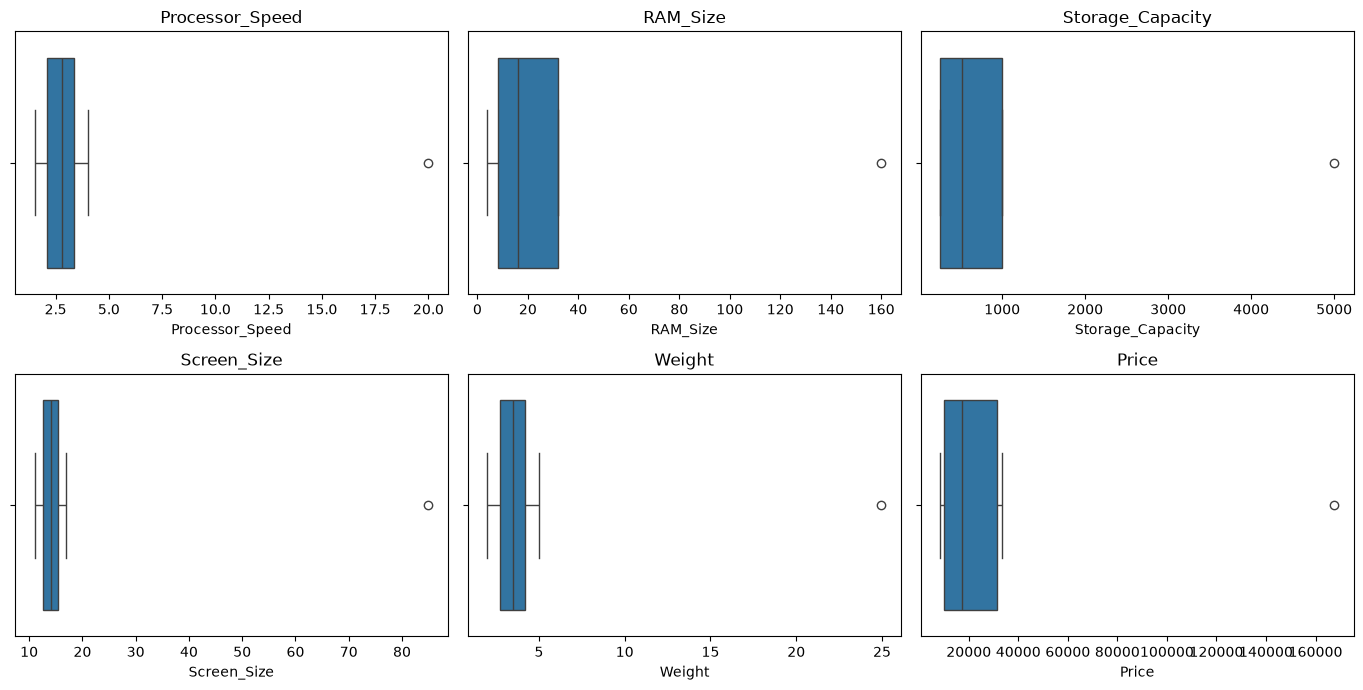

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
ax = ax.flat
for i, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=ax[i])
    ax[i].set_title(c)
plt.tight_layout()
plt.savefig('visuals/s1_boxplots.png', dpi=120)
plt.show()


In [12]:
# IQR check
for c in num_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5*iqr
    high = q3 + 1.5*iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    print(c, 'Q1=', round(q1,2), 'Q3=', round(q3,2), 'low=', round(low,2), 'high=', round(high,2), 'outliers=', n_out)


Processor_Speed Q1= 2.1 Q3= 3.35 low= 0.24 high= 5.21 outliers= 1
RAM_Size Q1= 8.0 Q3= 32.0 low= -28.0 high= 68.0 outliers= 1
Storage_Capacity Q1= 256.0 Q3= 1000.0 low= -860.0 high= 2116.0 outliers= 1
Screen_Size Q1= 12.67 Q3= 15.5 low= 8.43 high= 19.74 outliers= 1
Weight Q1= 2.73 Q3= 4.2 low= 0.53 high= 6.4 outliers= 1
Price Q1= 10188.05 Q3= 31551.75 low= -21857.5 high= 63597.31 outliers= 1


What I found: each column has only 1 outlier. Total 6 different rows. These are the same wrong values (160 RAM, 5000 storage, etc). I will remove these 6 rows because they are data entry mistakes and will spoil average and graphs. This is strict IQR rule as asked. After removal 994 rows remain (1000 - 6).

In [13]:
mask = pd.Series([False]*len(df))
for c in num_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5*iqr
    high = q3 + 1.5*iqr
    mask = mask | ((df[c] < low) | (df[c] > high))

print('rows to remove:', mask.sum())
df_clean = df[~mask].reset_index(drop=True)
print(df_clean.shape)
df_clean.to_csv('Laptop_price_cleaned_final.csv', index=False)
print('saved')


rows to remove: 6
(994, 7)
saved


## Step 6 - Final check

In [14]:
d = pd.read_csv('Laptop_price_cleaned_final.csv')
print(d.shape)
print(d.dtypes)
print('nulls:', d.isna().sum().sum())
print('duplicates:', d.duplicated().sum())
print(d['Brand'].unique())
print(d.describe().round(2))


(994, 7)
Brand                   str
Processor_Speed     float64
RAM_Size            float64
Storage_Capacity    float64
Screen_Size         float64
Weight              float64
Price               float64
dtype: object
nulls: 0
duplicates: 0
<ArrowStringArray>
['Lenovo', 'Acer', 'Asus', 'Dell', 'HP']
Length: 5, dtype: str


       Processor_Speed  RAM_Size  Storage_Capacity  Screen_Size  Weight  \
count           994.00    994.00            994.00       994.00  994.00   
mean              2.76     15.43            583.66        14.06    3.47   
std               0.72     10.84            310.52         1.68    0.86   
min               1.51      4.00            256.00        11.01    2.00   
25%               2.11      8.00            256.00        12.67    2.73   
50%               2.78     16.00            512.00        14.10    3.47   
75%               3.35     32.00           1000.00        15.50    4.19   
max               4.00     32.00           1000.00        16.99    4.99   

          Price  
count    994.00  
mean   19490.47  
std     9308.61  
min     8570.01  
25%    10154.56  
50%    17272.01  
75%    31551.13  
max    33503.94  


Final data is 994 rows and 7 columns. No nulls, no duplicates. Ready for EDA.

## My starting observations
- Brands: Dell 214, Asus 203, Acer 202, HP 188, Lenovo 187. All brands have good share.
- Price range after cleaning is 8570 to 33503. Mean is 19490, median is 17272. Mean is bigger, so some costly laptops pull average up.
- RAM has only 4, 8, 16, 32.
- Storage has only 256, 512, 1000. 1TB laptops look costly.
- Screen mostly 11 to 17 inch, middle value 14.1.
- Weight mostly 2 to 5 kg, middle value 3.47.
- Processor mostly 1.5 to 4.0, average 2.76.